In [1]:
import pandas as pd
import numpy as np
from scipy import stats
df = pd.read_csv (r"D:\CityU\5002\group_project\data_analysis\Preprocessing\BRFSS_2023_ACE_SCD_main.csv")

Variable Labeling and Derived Variables

In [2]:
# Sex
df["sex"] = df["SEXVAR"].map({1: "Male", 2: "Female"})

# Education
# (EDUCA 1-4 = High school or less; 5 = Attended college; 6 = College graduate)
df["education"] = df["EDUCA"].map({
    1: "High school or less",
    2: "High school or less",
    3: "High school or less",
    4: "High school or less",
    5: "Attended college",
    6: "College graduate"
})

# Marital status
df["marital"] = df["MARITAL"].map({
    1: "Married or living with partner",
    2: "Previously married",   # Divorced
    3: "Previously married",   # Widowed
    4: "Previously married",   # Separated
    5: "Never married",
    6: "Married or living with partner"   # Unmarried couple
})

# Annual household income: collapse the 11 original INCOME3 levels
# into 7 groups. INCOME3 coding (BRFSS 2023 codebook):
#   1=<$10k, 2=$10-15k, 3=$15-20k, 4=$20-25k, 5=$25-35k, 6=$35-50k,
#   7=$50-75k, 8=$75-100k, 9=$100-150k, 10=$150-200k, 11=>$200k
# NOTE: 17.95% missing income; kept as an explicit "Missing" category.
income_map = {
    1: "<$15k", 2: "<$15k",
    3: "$15-25k", 4: "$15-25k",
    5: "$25-35k",
    6: "$35-50k",
    7: "$50-100k", 8: "$50-100k",
    9: "$100-200k", 10: "$100-200k",
    11: ">=$200k"
}
df["income"] = df["INCOME3"].map(income_map).fillna("Missing")

# Binary poverty indicator, mirroring Voyer et al. (2023):
# household income below $25,000 vs $25,000 or more.
# (Voyer used $25k as the federal poverty level for a family of 3;
#  BRFSS reports household income, so this is an approximation.)
df["poverty"] = df["INCOME3"].apply(
    lambda x: "Below $25,000" if x in [1, 2, 3, 4]
    else (">=$25,000" if pd.notna(x) else None))

# Age groups
df["age_group"] = pd.cut(
    df["_AGE80"],
    bins=[44, 54, 64, 74, 80],
    labels=["45-54", "55-64", "65-74", "75+"]
)

# ACE cumulative score groups
# 0 / 1 / 2-3 / 4 or more ACEs
df["ace_group"] = pd.cut(
    df["ACE_score_11"],
    bins=[-1, 0, 1, 3, 11],
    labels=["0", "1", "2-3", "4+"]
)

# Race/ethnicity
df["race"] = df["_RACEGR3"].map({
    1: "White, non-Hispanic",
    2: "Black, non-Hispanic",
    3: "Others, non-Hispanic",
    4: "Others, non-Hispanic",
    5: "Hispanic"
})

# Obesity: _BMI5CAT 4 = obese (1=underweight, 2=normal, 3=overweight)
# Missing BMI is kept as NaN and excluded from Table 1.
df["obesity_bin"] = np.where(df["_BMI5CAT"].notna(),
                             (df["_BMI5CAT"] == 4).astype(float), np.nan)

# Diabetes: DIABETE4 1 = yes. Code 2 (gestational only) and code 4
# (pre-diabetes/borderline) are counted as no; missing stays NaN.
df["diabetes_bin"] = np.where(df["DIABETE4"].notna(),
                              (df["DIABETE4"] == 1).astype(float), np.nan)

# Smoking status (_SMOKER3): collapse 4 levels into 3
# 1=every day + 2=some days -> Current smoker; 3=Former; 4=Never
df["smoking"] = df["_SMOKER3"].map({
    1: "Current smoker",
    2: "Current smoker",
    3: "Former smoker",
    4: "Never smoked"
})

# State mapping
fips_to_state = {
    1: ("Alabama", "AL"), 2: ("Alaska", "AK"), 4: ("Arizona", "AZ"), 5: ("Arkansas", "AR"),
    6: ("California", "CA"), 8: ("Colorado", "CO"), 9: ("Connecticut", "CT"), 10: ("Delaware", "DE"),
    11: ("District of Columbia", "DC"), 12: ("Florida", "FL"), 13: ("Georgia", "GA"), 15: ("Hawaii", "HI"),
    16: ("Idaho", "ID"), 17: ("Illinois", "IL"), 18: ("Indiana", "IN"), 19: ("Iowa", "IA"),
    20: ("Kansas", "KS"), 21: ("Kentucky", "KY"), 22: ("Louisiana", "LA"), 23: ("Maine", "ME"),
    24: ("Maryland", "MD"), 25: ("Massachusetts", "MA"), 26: ("Michigan", "MI"), 27: ("Minnesota", "MN"),
    28: ("Mississippi", "MS"), 29: ("Missouri", "MO"), 30: ("Montana", "MT"), 31: ("Nebraska", "NE"),
    32: ("Nevada", "NV"), 33: ("New Hampshire", "NH"), 34: ("New Jersey", "NJ"), 35: ("New Mexico", "NM"),
    36: ("New York", "NY"), 37: ("North Carolina", "NC"), 38: ("North Dakota", "ND"), 39: ("Ohio", "OH"),
    40: ("Oklahoma", "OK"), 41: ("Oregon", "OR"), 42: ("Pennsylvania", "PA"), 44: ("Rhode Island", "RI"),
    45: ("South Carolina", "SC"), 46: ("South Dakota", "SD"), 47: ("Tennessee", "TN"), 48: ("Texas", "TX"),
    49: ("Utah", "UT"), 50: ("Vermont", "VT"), 51: ("Virginia", "VA"), 53: ("Washington", "WA"),
    54: ("West Virginia", "WV"), 55: ("Wisconsin", "WI"), 56: ("Wyoming", "WY"),
    66: ("Guam", "GU"), 72: ("Puerto Rico", "PR"), 78: ("Virgin Islands", "VI")
}
df["state_name"] = df["_STATE"].map(lambda x: fips_to_state.get(int(x), ("Unknown", "??"))[0])
df["state_abbr"] = df["_STATE"].map(lambda x: fips_to_state.get(int(x), ("Unknown", "??"))[1])

Sanity Check

In [3]:
# Distribution of each newly created variable
for col in ["sex", "education", "marital", "income", "age_group", "ace_group"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

# States covered by the analytic sample
print("Number of states:", df["state_abbr"].nunique())
print(df.groupby(["state_abbr", "state_name"]).size().sort_values(ascending=False))

--- sex ---
sex
Female    20127
Male      15627
Name: count, dtype: int64

--- education ---
education
College graduate       16098
High school or less    10248
Attended college        9312
NaN                       96
Name: count, dtype: int64

--- marital ---
marital
Married or living with partner    20773
Previously married                12030
Never married                      2735
NaN                                 216
Name: count, dtype: int64

--- income ---
income
$50-100k     9155
$100-200k    6456
Missing      6418
$35-50k      3865
$25-35k      3287
$15-25k      2795
>=$200k      2301
<$15k        1477
Name: count, dtype: int64

--- age_group ---
age_group
65-74    11042
75+       9342
55-64     8959
45-54     6411
Name: count, dtype: int64

--- ace_group ---
ace_group
0      14342
1       8245
2-3     7649
4+      5518
Name: count, dtype: int64

Number of states: 10
state_abbr  state_name  
FL          Florida         7010
NJ          New Jersey      4668
GA          Geor

Table 1: Characteristics

In [4]:
# Table 1: Characteristics by SCD status
# Counts are unweighted; percentages are weighted with the final
# BRFSS weight (_LLCPWT). P values come from a design-based Wald
# chi-square test (Taylor linearization with _STSTR and _PSU).

def survey_wald_p(data, var, outcome="SCD", weight="_LLCPWT",
                  strata="_STSTR", psu="_PSU"):
    """
    Design-based Wald chi-square test for independence between
    a categorical variable and a binary outcome.
    Returns (chi2, df, p_value). Missing values are excluded.
    """
    d = data[[var, outcome, weight, strata, psu]].dropna()
    levels = list(pd.unique(d[var]))
    g1 = (d[outcome] == 1).to_numpy(float)
    g0 = 1 - g1
    w = d[weight].to_numpy(float)
    W1, W0 = (w * g1).sum(), (w * g0).sum()

    diffs, u_cols = [], []
    for k, lev in enumerate(levels[:-1]):  # drop last level to keep full rank
        ind = (d[var] == lev).to_numpy(float)
        p1 = (w * g1 * ind).sum() / W1
        p0 = (w * g0 * ind).sum() / W0
        diffs.append(p1 - p0)
        col = f"_u{k}"
        d[col] = w * (g1 * (ind - p1) / W1 - g0 * (ind - p0) / W0)  # linearized variable
        u_cols.append(col)

    # Taylor variance-covariance from PSU totals within strata
    cov = np.zeros((len(u_cols), len(u_cols)))
    for s, gdf in d.groupby(strata):
        totals = gdf.groupby(psu)[u_cols].sum()
        n_h = len(totals)
        if n_h > 1:
            dev = totals - totals.mean()
            cov += n_h / (n_h - 1) * (dev.T @ dev).to_numpy()

    diffs = np.array(diffs)
    chi2 = float(diffs @ np.linalg.pinv(cov) @ diffs)
    dfree = len(diffs)
    return chi2, dfree, float(stats.chi2.sf(chi2, dfree))


def fmt_p(p):
    """Format p-values in journal style."""
    return "<.001" if p < 0.001 else f"{p:.3f}".lstrip("0")


def voyer_block(data, var, var_label, level_order=None, single_level=None):
    """
    Table rows for one variable: unweighted n (weighted %) by SCD status,
    with the design-adjusted Wald p-value on the variable header row.
    single_level: for binary indicators, show only that level (e.g., poverty).
    """
    d = data[[var, "SCD", "_LLCPWT"]].dropna()
    chi2, dof, p = survey_wald_p(data, var)
    W0 = d.loc[d["SCD"] == 0, "_LLCPWT"].sum()
    W1 = d.loc[d["SCD"] == 1, "_LLCPWT"].sum()

    def cell(sel):
        n0 = int((sel & (d["SCD"] == 0)).sum())
        n1 = int((sel & (d["SCD"] == 1)).sum())
        w0 = 100 * d.loc[sel & (d["SCD"] == 0), "_LLCPWT"].sum() / W0
        w1 = 100 * d.loc[sel & (d["SCD"] == 1), "_LLCPWT"].sum() / W1
        return f"{n0:,} ({w0:.1f})", f"{n1:,} ({w1:.1f})"

    if single_level is not None:
        c0, c1 = cell(d[var] == single_level)
        return [{"Characteristics": var_label, COL0: c0, COL1: c1, "P value": fmt_p(p)}]

    rows = [{"Characteristics": var_label, COL0: "", COL1: "", "P value": fmt_p(p)}]
    for lev in level_order:
        c0, c1 = cell(d[var] == lev)
        rows.append({"Characteristics": f"  {lev}", COL0: c0, COL1: c1, "P value": ""})
    return rows

Table1  Characteristics of the analytic sample

In [5]:
N0 = int((df["SCD"] == 0).sum())
N1 = int((df["SCD"] == 1).sum())
COL0 = f"Without SCD (n={N0:,}), n (%)"
COL1 = f"With SCD (n={N1:,}), n (%)"

rows = [{"Characteristics": "Demographics", COL0: "", COL1: "", "P value": ""}]
rows += voyer_block(df, "sex", "Sex", ["Male", "Female"])
rows += voyer_block(df, "age_group", "Age group, y", ["45-54", "55-64", "65-74", "75+"])
rows += voyer_block(df, "education", "Education",
                    ["High school or less", "Attended college", "College graduate"])
rows += voyer_block(df, "poverty", "Annual income below $25,000",
                    single_level="Below $25,000")
rows += voyer_block(df, "marital", "Marital status",
                    ["Married or living with partner", "Previously married", "Never married"])

rows += voyer_block(df, "race", "Race/ethnicity",
                    ["White, non-Hispanic", "Black, non-Hispanic",
                     "Hispanic", "Others, non-Hispanic"])


rows += [{"Characteristics": "ACE exposure", COL0: "", COL1: "", "P value": ""}]
rows += voyer_block(df, "ace_group", "ACE score group", ["0", "1", "2-3", "4+"])

# Health conditions
rows += [{"Characteristics": "Health conditions", COL0: "", COL1: "", "P value": ""}]
rows += voyer_block(df, "Depression_bin", "Depressive disorder", single_level=1)
rows += voyer_block(df, "diabetes_bin", "Diabetes", single_level=1)
rows += voyer_block(df, "Stroke_bin", "Stroke", single_level=1)
rows += voyer_block(df, "obesity_bin", "Obesity", single_level=1)
rows += voyer_block(df, "HighBP_bin", "Hypertension", single_level=1)

# Report the INACTIVE level (bin = 0), mirroring Voyer's "Physical inactivity" row
rows += voyer_block(df, "PhysicalActivity_bin", "Physical inactivity", single_level=0)
rows += voyer_block(df, "smoking", "Smoking status",
                    ["Current smoker", "Former smoker", "Never smoked"])


table1 = pd.DataFrame(rows)
table1.to_csv("Table1_characteristics_by_SCD.csv", index=False, encoding="utf-8-sig")
table1

,Characteristics,"Without SCD (n=29,641), n (%)","With SCD (n=6,113), n (%)",P value
0,Demographics,,,
1,Sex,,,<.001
2,Male,"13,089 (47.0)","2,538 (41.1)",
3,Female,"16,552 (53.0)","3,575 (58.9)",
4,"Age group, y",,,<.001
5,45-54,"5,386 (25.5)","1,025 (22.2)",
6,55-64,"7,443 (29.2)","1,516 (28.8)",
7,65-74,"9,332 (26.9)","1,710 (25.6)",
8,75+,"7,480 (18.4)","1,862 (23.4)",
9,Education,,,<.001


Figure1 

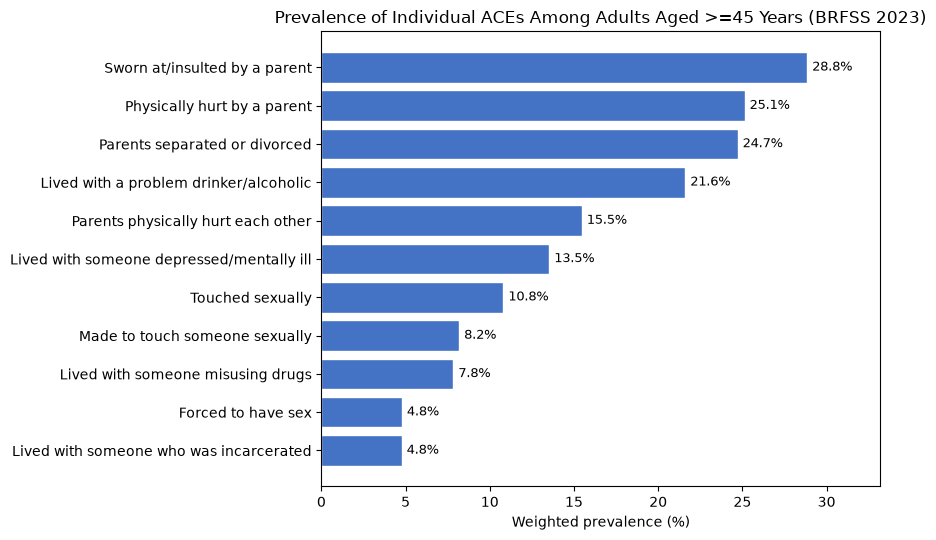

In [6]:
# Figure 1: Weighted prevalence of each of the 11 ACE items

import matplotlib.pyplot as plt

# Readable labels for the 11 ACE indicators
ace_labels = {
    "ACEDEPRS_bin": "Lived with someone depressed/mentally ill",
    "ACEDRINK_bin": "Lived with a problem drinker/alcoholic",
    "ACEDRUGS_bin": "Lived with someone misusing drugs",
    "ACEPRISN_bin": "Lived with someone who was incarcerated",
    "ACEDIVRC_bin": "Parents separated or divorced",
    "ACEPUNCH_bin": "Parents physically hurt each other",
    "ACEHURT1_bin": "Physically hurt by a parent",
    "ACESWEAR_bin": "Sworn at/insulted by a parent",
    "ACETOUCH_bin": "Touched sexually",
    "ACETTHEM_bin": "Made to touch someone sexually",
    "ACEHVSEX_bin": "Forced to have sex",
}

# Weighted prevalence of each ACE item
total_w = df["_LLCPWT"].sum()
prev = pd.Series({
    lab: 100 * df.loc[df[col] == 1, "_LLCPWT"].sum() / total_w
    for col, lab in ace_labels.items()
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(prev.index, prev.values, color="#4472C4", edgecolor="white")
for i, v in enumerate(prev.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Weighted prevalence (%)")
ax.set_title("Prevalence of Individual ACEs Among Adults Aged >=45 Years (BRFSS 2023)")
ax.set_xlim(0, prev.max() * 1.15)
plt.tight_layout()
plt.savefig("Fig1_ACE_prevalence.png", dpi=300)   # 300 dpi for the report
plt.show()

Figure2

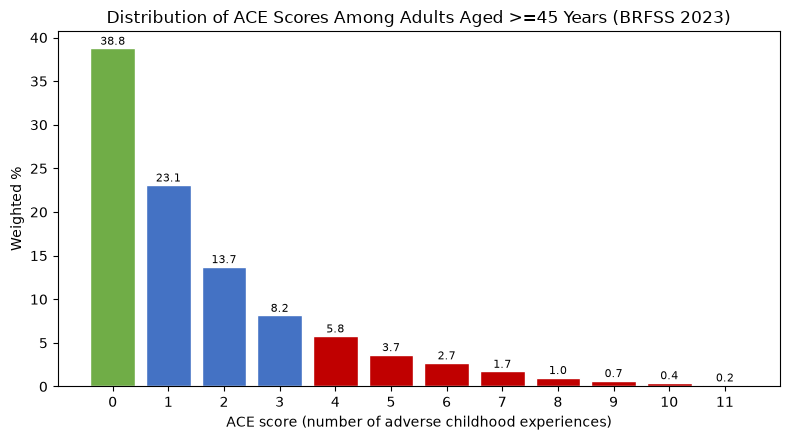

In [7]:
# Figure 2: Distribution of the cumulative ACE score (0-11)
# Colors mark the ACE groups: 0 (green), 1-3 (blue), 4+ (red)

score_w = df.groupby("ACE_score_11")["_LLCPWT"].sum() / df["_LLCPWT"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#70AD47" if s == 0 else "#4472C4" if s < 4 else "#C00000"
          for s in score_w.index]
ax.bar(score_w.index.astype(int), score_w.values, color=colors, edgecolor="white")
for x, v in score_w.items():
    ax.text(int(x), v + 0.4, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xlabel("ACE score (number of adverse childhood experiences)")
ax.set_ylabel("Weighted %")
ax.set_title("Distribution of ACE Scores Among Adults Aged >=45 Years (BRFSS 2023)")
ax.set_xticks(range(12))
plt.tight_layout()
plt.savefig("Fig2_ACE_score_distribution.png", dpi=300)
plt.show()

Calculate prevalence of SCD in subgroups

In [8]:
# Figures 3-6: Weighted SCD prevalence by subgroup, with 95% CI
# (error bars from Taylor linearization using strata and PSU)

def wtd_mean_se(y, w, strata, psu):
    """Weighted proportion and its design-based SE (Taylor linearization)."""
    d = pd.DataFrame({"y": y, "w": w, "strata": strata, "psu": psu}).dropna()
    y, w = d["y"].to_numpy(float), d["w"].to_numpy(float)
    p = (y * w).sum() / w.sum()
    d["z"] = w * (y - p)
    var = 0.0
    for s, g in d.groupby("strata"):
        psu_sum = g.groupby("psu")["z"].sum()
        n_h = len(psu_sum)
        if n_h > 1:
            var += n_h / (n_h - 1) * ((psu_sum - psu_sum.mean()) ** 2).sum()
    return p, np.sqrt(var) / w.sum()


def scd_by(var, order):
    """Weighted SCD prevalence with 95% CI for each level of a variable."""
    rows = []
    for lev in order:
        m = df[var] == lev
        p, se = wtd_mean_se(df.loc[m, "SCD"], df.loc[m, "_LLCPWT"],
                            df.loc[m, "_STSTR"], df.loc[m, "_PSU"])
        rows.append({"level": lev, "prev": 100 * p,
                     "lo": 100 * (p - 1.96 * se), "hi": 100 * (p + 1.96 * se),
                     "n": int(m.sum())})
    return pd.DataFrame(rows)

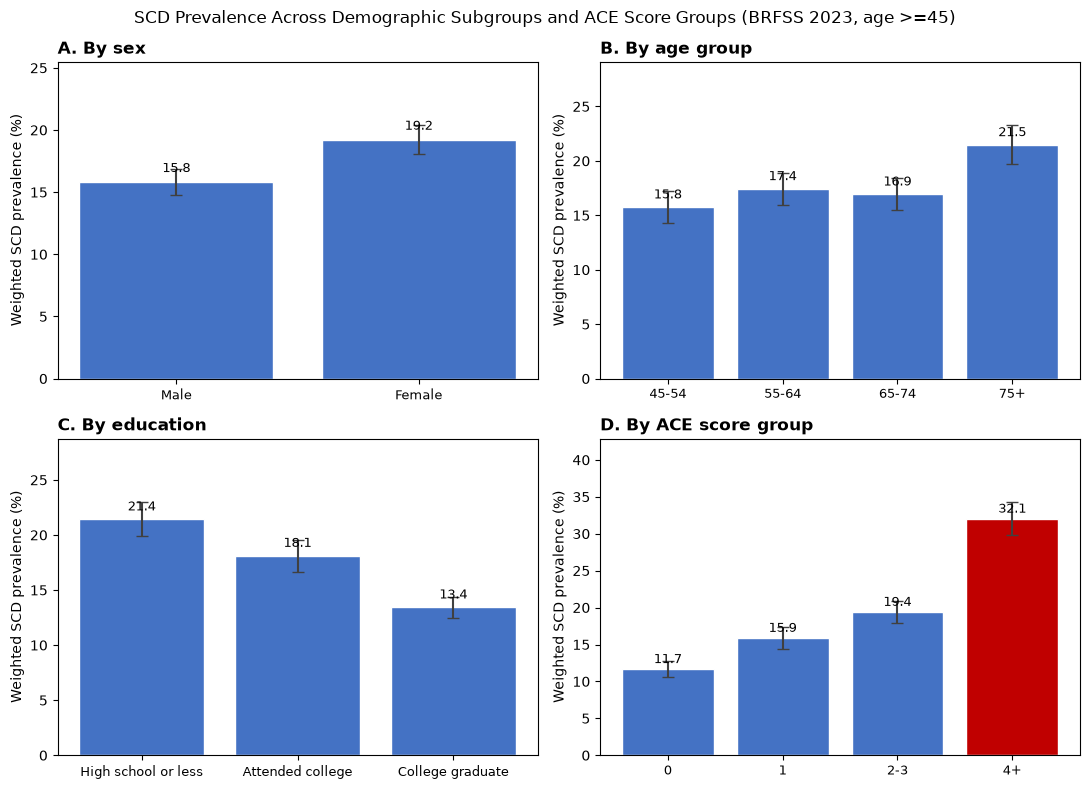

In [9]:
# Four-panel figure: SCD prevalence by sex, age, education, ACE group
panels = [
    ("sex", ["Male", "Female"], "A. By sex"),
    ("age_group", ["45-54", "55-64", "65-74", "75+"], "B. By age group"),
    ("education", ["High school or less", "Attended college", "College graduate"],
     "C. By education"),
    ("ace_group", ["0", "1", "2-3", "4+"], "D. By ACE score group"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (var, order, title) in zip(axes.flat, panels):
    r = scd_by(var, order)
    x = np.arange(len(r))
    colors = ["#C00000" if (var == "ace_group" and l == "4+") else "#4472C4"
              for l in r["level"]]
    ax.bar(x, r["prev"], yerr=[r["prev"] - r["lo"], r["hi"] - r["prev"]],
           capsize=4, color=colors, edgecolor="white",
           error_kw=dict(ecolor="#404040"))
    for i, v in enumerate(r["prev"]):
        ax.text(i, v + 0.8, f"{v:.1f}", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(r["level"], fontsize=9)
    ax.set_ylabel("Weighted SCD prevalence (%)")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylim(0, max(r["hi"]) * 1.25)

fig.suptitle("SCD Prevalence Across Demographic Subgroups and ACE Score Groups "
             "(BRFSS 2023, age >=45)", fontsize=12)
plt.tight_layout()
plt.savefig("Fig3-6_SCD_by_subgroups.png", dpi=300)
plt.show()

Figure Maps

In [10]:
# %pip install "kaleido>=1"

In [12]:
# Figure - State-level SCD prevalence
#       Combined bubble map + ranked bar chart (plotly)
# Design rationale:
#   Left panel  = real US map, one bubble per state at its geographic
#                 center. Bubble SIZE = unweighted n (reliability),
#                 bubble COLOR = weighted SCD prevalence.
#   Right panel = same states ranked as horizontal bars, with exact
#                 prevalence and n annotated.
#   Both panels share the same color scale (YlOrRd, 8-24%).

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# --- Step 1: state-level weighted SCD prevalence + unweighted n ---
fips10 = {10:"DE", 12:"FL", 13:"GA", 29:"MO", 32:"NV",
          34:"NJ", 41:"OR", 44:"RI", 47:"TN", 51:"VA"}
# Full state names for display labels
state_names = {"DE":"Delaware", "FL":"Florida", "GA":"Georgia",
               "MO":"Missouri", "NV":"Nevada", "NJ":"New Jersey",
               "OR":"Oregon", "RI":"Rhode Island", "TN":"Tennessee",
               "VA":"Virginia"}

df["abbr"] = df["_STATE"].map(fips10)
df["state"] = df["abbr"].map(state_names)

st = (df.dropna(subset=["SCD", "_LLCPWT"])
        .groupby(["abbr", "state"])
        .apply(lambda g: pd.Series({
            "prev": np.average(g["SCD"], weights=g["_LLCPWT"]) * 100,
            "n": len(g)}), include_groups=False)
        .reset_index()
        .sort_values("prev", ascending=False)   # largest first
        .reset_index(drop=True))

# Approximate geographic center of each state (lat, lon) for the bubbles
centroids = {"DE":(39.0,-75.5), "FL":(27.8,-81.7), "GA":(32.7,-83.4),
             "MO":(38.5,-92.5), "NV":(39.5,-116.9), "NJ":(40.1,-74.7),
             "OR":(43.9,-120.6), "RI":(41.7,-71.6), "TN":(35.8,-86.4),
             "VA":(37.5,-78.9)}

# --- Step 2: canvas with a geo panel (left) and a bar panel (right) ---

fig = make_subplots(rows=1, cols=2,
                    specs=[[{"type": "geo"}, {"type": "xy"}]],
                    column_widths=[0.55, 0.45],
                    horizontal_spacing=0.15,   # gap between the two panels
                    subplot_titles=("Bubble map (size = n, color = prevalence)",
                                    "Ranked prevalence"))
# --- Step 3: bubble map ---
fig.add_trace(go.Scattergeo(
    lat=[centroids[a][0] for a in st["abbr"]],
    lon=[centroids[a][1] for a in st["abbr"]],
    text=st["state"],                     # full state name next to each bubble
    mode="markers+text", textposition="top center",
    hovertemplate="%{text}: %{marker.color:.1f}% "
                  "(n=%{marker.size:,})<extra></extra>",
    marker=dict(
        size=st["n"], sizemode="area",    # bubble AREA proportional to n
        sizeref=2. * st["n"].max() / (55 ** 2),  # scale: max bubble ~55 px
        sizemin=8,
        color=st["prev"], colorscale="YlOrRd", cmin=8, cmax=24,
        colorbar=dict(title="SCD %", x=0.45, len=0.7),
        line=dict(color="white", width=1)),
    showlegend=False), row=1, col=1)

fig.update_geos(scope="usa", showland=True, landcolor="#f0f0f0",
                showlakes=False, row=1, col=1)

# --- Step 4: ranked bars, colors consistent with the map ---
cmap = plt.get_cmap("YlOrRd")
norm = mcolors.Normalize(vmin=8, vmax=24)
hexcolors = [mcolors.to_hex(cmap(norm(v))) for v in st["prev"]]

fig.add_trace(go.Bar(
    y=st["state"], x=st["prev"], orientation="h",
    marker_color=hexcolors,
    text=[f"{v:.1f}%  (n={int(n):,})" for v, n in zip(st["prev"], st["n"])],
    textposition="outside", showlegend=False), row=1, col=2)

fig.update_yaxes(autorange="reversed", row=1, col=2)   # largest on top
fig.update_xaxes(range=[0, 27],
                 title_text="Weighted SCD prevalence (%)", row=1, col=2)

fig.update_layout(
    title_text="SCD Prevalence by State — BRFSS 2023, ages 45+ "
               "(10 states with ACE module)",
    width=1150, height=520, margin=dict(t=80))

fig.update_xaxes(range=[0, 32],
                 title_text="Weighted SCD prevalence (%)", row=1, col=2)
fig.update_layout(
    title_text="SCD Prevalence by State — BRFSS 2023, ages 45+ "
               "(10 states with ACE module)",
    width=1150, height=520, margin=dict(t=80, r=130))
fig.write_image("Fig7_SCD_by_state_bubble_bar.png", scale=3)   # AFTER final layout
fig.show()